[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SaiAnirudh659/datMan_SaiAnirudhKasarla/blob/main/239001405_datMan_ps2.ipynb)

# Problem Set 2: Mapping Urban Tree Density, PM2.5, and Pediatric Asthma in Philadelphia

### RUID: 239001405
### Name: Sai Anirudh Kasarla

## Project Description

This project investigates the geographic relationship between urban tree distribution, fine particulate matter (PM2.5), and pediatric asthma prevalence across Philadelphia census tracts.

Building on the research conducted in Problem Sets 0 and 1, this notebook introduces the 2025 Philadelphia Tree Inventory as an additional environmental dataset. Spatial joins are used to connect tree locations with census tract boundaries and existing health and environmental data.

## Research Question

**How does urban tree density vary across Philadelphia, and what geographic patterns emerge when compared with PM2.5 exposure and pediatric asthma prevalence?**

## Project Objectives

1. Integrate three geographic datasets using spatial and attribute joins.
2. Calculate the number of inventoried trees per square kilometer for each census tract.
3. Create geographic maps showing tree density, PM2.5, and pediatric asthma.
4. Compare spatial patterns and identify areas for further investigation.
5. Interpret the findings while acknowledging differences in data collection periods and limitations.

## Unit of Analysis

Philadelphia County, Pennsylvania — 2010 Census Tracts.

## New Dataset for PS2

**Philadelphia Tree Inventory (2025)**

Source: [OpenDataPhilly — Philadelphia Tree Inventory](https://opendataphilly.org/datasets/philadelphia-tree-inventory/)

The inventory contains 151,726 tree records, of which 151,372 were spatially assigned to the census tract boundaries used in this project.

In [1]:
# ============================================================
# Problem Set 2 - Philadelphia Environmental Spatial Analysis
# Step 1: Install and import required libraries
# ============================================================

!pip -q install geopandas mapclassify

import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import requests
import io

from IPython.display import display

# Plot settings
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 11

print("PS2 environment is ready!")
print("GeoPandas version:", gpd.__version__)

PS2 environment is ready!
GeoPandas version: 1.2.0


In [2]:
# PS2 - Load Philadelphia 2010 Census Tract Boundaries
# Source: City of Philadelphia Open Data (CARTO)

tract_url = "https://phl.carto.com/api/v2/sql"

tract_params = {
    "q": "SELECT geoid10, the_geom FROM census_tracts_2010",
    "format": "GeoJSON"
}

tract_response = requests.get(
    tract_url,
    params=tract_params,
    timeout=120
)

print("HTTP Status:", tract_response.status_code)
tract_response.raise_for_status()

philly_tracts = gpd.read_file(
    io.BytesIO(tract_response.content)
)

# Ensure census tract IDs are strings
philly_tracts["geoid10"] = (
    philly_tracts["geoid10"].astype(str).str.zfill(11)
)

print("Philadelphia census tracts loaded!")
print("Total tracts:", len(philly_tracts))
print("Coordinate system:", philly_tracts.crs)
print("Columns:", philly_tracts.columns.tolist())

display(philly_tracts.head())

HTTP Status: 200
Philadelphia census tracts loaded!
Total tracts: 384
Coordinate system: EPSG:4326
Columns: ['geoid10', 'geometry']


,geoid10,geometry
0,42101980200,"MULTIPOLYGON (((-75.05636 40.08766, -75.05644 ..."
1,42101980100,"MULTIPOLYGON (((-75.22445 40.07912, -75.22346 ..."
2,42101980800,"MULTIPOLYGON (((-75.25593 39.97813, -75.25566 ..."
3,42101014500,"MULTIPOLYGON (((-75.14936 39.97326, -75.15032 ..."
4,42101000600,"MULTIPOLYGON (((-75.16394 39.95087, -75.16386 ..."


In [3]:
# PS2 - Load pediatric asthma data from CDC PLACES

CDC_PLACES_URL = (
    "https://data.cdc.gov/resource/cwsq-ngmh.csv"
    "?$limit=50000&stateabbr=PA"
)

cdc_df = pd.read_csv(CDC_PLACES_URL)

print("CDC PLACES data loaded successfully!")
print("Total records:", len(cdc_df))
print("Available columns:")
print(cdc_df.columns.tolist())

display(cdc_df.head())

CDC PLACES data loaded successfully!
Total records: 17037
Available columns:
['year', 'stateabbr', 'statedesc', 'countyname', 'countyfips', 'locationname', 'datasource', 'category', 'measure', 'data_value_unit', 'data_value_type', 'data_value', 'data_value_footnote_symbol', 'data_value_footnote', 'low_confidence_limit', 'high_confidence_limit', 'totalpopulation', 'totalpop18plus', 'geolocation', 'locationid', 'categoryid', 'measureid', 'datavaluetypeid', 'short_question_text']


,year,stateabbr,statedesc,countyname,countyfips,locationname,datasource,category,measure,data_value_unit,...,low_confidence_limit,high_confidence_limit,totalpopulation,totalpop18plus,geolocation,locationid,categoryid,measureid,datavaluetypeid,short_question_text
0,2022,PA,Pennsylvania,Allegheny,42003,42003270100,BRFSS,Health Outcomes,All teeth lost among adults aged >=65 years,%,...,9.7,14.3,2578,2098,POINT (-80.0429221 40.4826334),42003270100,HLTHOUT,TEETHLOST,CrdPrv,All Teeth Lost
1,2022,PA,Pennsylvania,Allegheny,42003,42003191500,BRFSS,Prevention,Visited dentist or dental clinic in the past y...,%,...,61.0,67.1,2005,1803,POINT (-80.0108171 40.4205204),42003191500,PREVENT,DENTAL,CrdPrv,Dental Visit
2,2022,PA,Pennsylvania,Allegheny,42003,42003101900,BRFSS,Health Outcomes,All teeth lost among adults aged >=65 years,%,...,16.7,23.9,2432,1839,POINT (-79.9401262 40.4687735),42003101900,HLTHOUT,TEETHLOST,CrdPrv,All Teeth Lost
3,2022,PA,Pennsylvania,Allegheny,42003,42003429100,BRFSS,Prevention,Mammography use among women aged 50-74 years,%,...,73.9,84.5,2607,2132,POINT (-80.0077199 40.5062553),42003429100,PREVENT,MAMMOUSE,CrdPrv,Mammography
4,2022,PA,Pennsylvania,Allegheny,42003,42003020100,BRFSS,Prevention,Mammography use among women aged 50-74 years,%,...,72.7,84.0,4729,4586,POINT (-80.001277 40.4406616),42003020100,PREVENT,MAMMOUSE,CrdPrv,Mammography


In [4]:
# PS2 - Identify asthma measurements for Philadelphia

# Filter CDC data to Philadelphia County
philly_cdc = cdc_df[
    cdc_df["countyname"].astype(str).str.lower() == "philadelphia"
].copy()

print("Philadelphia records:", len(philly_cdc))

# Find all asthma-related measurements
asthma_records = philly_cdc[
    philly_cdc["measure"].astype(str).str.contains(
        "asthma", case=False, na=False
    )
].copy()

print("Philadelphia asthma records:", len(asthma_records))

print("\nAvailable asthma measurements:")
print(asthma_records["measure"].value_counts())

display(
    asthma_records[
        ["year", "locationname", "measure", "data_value"]
    ].head(10)
)

Philadelphia records: 1945
Philadelphia asthma records: 0

Available asthma measurements:
Series([], Name: count, dtype: int64)


,year,locationname,measure,data_value


In [5]:
# Check which health measurements are available

print("Available CDC measurements:")
print(philly_cdc["measure"].value_counts().to_string())

print("\nAvailable years:")
print(philly_cdc["year"].value_counts())

print("\nAsthma records in the entire downloaded dataset:")
print(
    cdc_df[
        cdc_df["measure"].astype(str).str.contains(
            "asthma", case=False, na=False
        )
    ]["measure"].value_counts()
)

Available CDC measurements:
measure
Short sleep duration among adults                                 389
Colorectal cancer screening among adults aged 45–75 years         389
All teeth lost among adults aged >=65 years                       389
Visited dentist or dental clinic in the past year among adults    389
Mammography use among women aged 50-74 years                      389

Available years:
year
2022    1945
Name: count, dtype: int64

Asthma records in the entire downloaded dataset:
Series([], Name: count, dtype: int64)


In [6]:
# PS2 - Download Philadelphia asthma data directly

import requests
import pandas as pd

url = "https://data.cdc.gov/resource/cwsq-ngmh.json"

params = {
    "$where": "countyname='Philadelphia' AND lower(measure) like '%asthma%'",
    "$limit": 50000
}

response = requests.get(url, params=params, timeout=90)
response.raise_for_status()

asthma_df = pd.DataFrame(response.json())

print("Asthma records downloaded:", len(asthma_df))

if not asthma_df.empty:
    print("\nAvailable asthma measurements:")
    print(asthma_df["measure"].value_counts())
    print("\nAvailable years:")
    print(asthma_df["year"].value_counts())
    display(asthma_df.head())
else:
    print("No matching asthma records. We need to check the dataset's measure codes.")

Asthma records downloaded: 0
No matching asthma records. We need to check the dataset's measure codes.


In [7]:
# PS2 - Prepare Philadelphia census tracts for spatial analysis

philly_tracts["geoid10"] = (
    philly_tracts["geoid10"].astype(str).str.zfill(11)
)

# Convert to a projected coordinate system for accurate area calculations
philly_tracts = philly_tracts.to_crs(epsg=26918)

# Calculate census tract area in square kilometers
philly_tracts["area_km2"] = philly_tracts.geometry.area / 1_000_000

print("Total Philadelphia census tracts:", len(philly_tracts))
print("Coordinate system:", philly_tracts.crs)

display(philly_tracts[["geoid10", "area_km2"]].head())

Total Philadelphia census tracts: 384
Coordinate system: EPSG:26918


,geoid10,area_km2
0,42101980200,5.387377
1,42101980100,5.889534
2,42101980800,2.169229
3,42101014500,0.321188
4,42101000600,0.172547


In [8]:
# PS2 - Download Philadelphia Tree Inventory (2025)
# Source: ArcGIS Hub / OpenDataPhilly

import geopandas as gpd
import requests
import io

tree_url = (
    "https://hub.arcgis.com/api/v3/datasets/"
    "dc6826e1319c4b35a7b662bc6be68104_0/"
    "downloads/data"
)

params = {
    "format": "geojson",
    "spatialRefId": 4326,
    "where": "1=1"
}

response = requests.get(
    tree_url,
    params=params,
    timeout=180
)

print("HTTP Status:", response.status_code)
response.raise_for_status()

trees_gdf = gpd.read_file(
    io.BytesIO(response.content)
)

print("Tree inventory loaded successfully!")
print("Number of tree records:", len(trees_gdf))
print("Coordinate system:", trees_gdf.crs)

display(trees_gdf.head())

HTTP Status: 200
Tree inventory loaded successfully!
Number of tree records: 151726
Coordinate system: EPSG:4326


,objectid,tree_name,tree_dbh,year,loc_y,loc_x,geometry
0,1,GINKGO BILOBA - GINKGO,36.0,2025,39.983823,-75.210501,POINT (-75.2105 39.98383)
1,2,ACER PALMATUM - JAPANESE MAPLE,NaN,2025,39.983734,-75.210532,POINT (-75.21053 39.98374)
2,3,ACER PALMATUM - JAPANESE MAPLE,8.0,2025,39.983749,-75.210405,POINT (-75.21041 39.98376)
3,4,ACER PALMATUM - JAPANESE MAPLE,12.0,2025,39.983943,-75.210602,POINT (-75.2106 39.98395)
4,5,ACER PSEUDOPLATANUS - SYCAMORE MAPLE,17.0,2025,39.983754,-75.210273,POINT (-75.21028 39.98376)


In [9]:

# PS2 - Spatial join: assign trees to Philadelphia census tracts

# Match coordinate systems before the spatial join
trees_projected = trees_gdf.to_crs(philly_tracts.crs)

# Keep only tree locations and census tract identifiers
trees_joined = gpd.sjoin(
    trees_projected[["geometry"]],
    philly_tracts[["geoid10", "geometry"]],
    how="inner",
    predicate="within"
)

# Count trees in each census tract
tree_counts = (
    trees_joined.groupby("geoid10")
    .size()
    .reset_index(name="tree_count")
)

# Include census tracts with no matched trees
philly_tree_data = philly_tracts.merge(
    tree_counts,
    on="geoid10",
    how="left"
)

philly_tree_data["tree_count"] = (
    philly_tree_data["tree_count"].fillna(0).astype(int)
)

# Calculate inventoried trees per square kilometer
philly_tree_data["tree_density"] = (
    philly_tree_data["tree_count"] /
    philly_tree_data["area_km2"]
)

print("Total census tracts:", len(philly_tree_data))
print("Trees assigned to census tracts:", len(trees_joined))
print("Total trees counted:", philly_tree_data["tree_count"].sum())

display(
    philly_tree_data[
        ["geoid10", "area_km2", "tree_count", "tree_density"]
    ].head()
)

Total census tracts: 384
Trees assigned to census tracts: 151372
Total trees counted: 151372


,geoid10,area_km2,tree_count,tree_density
0,42101980200,5.387377,891,165.386607
1,42101980100,5.889534,1105,187.620963
2,42101980800,2.169229,2227,1026.631887
3,42101014500,0.321188,417,1298.306446
4,42101000600,0.172547,203,1176.490656


In [10]:

# Load the completed PS1 notebook and recover its merged dataset
import requests
import nbformat
from IPython import get_ipython

ps1_url = "https://raw.githubusercontent.com/SaiAnirudh659/datMan_SaiAnirudhKasarla/main/239001405_datMan_ps1.ipynb"

response = requests.get(ps1_url, timeout=60)
response.raise_for_status()

ps1_notebook = nbformat.reads(response.text, as_version=4)

print("PS1 notebook loaded.")
print("Code cells found:", sum(
    cell.cell_type == "code" for cell in ps1_notebook.cells
))

# Locate the code cell that creates philly_merged
for i, cell in enumerate(ps1_notebook.cells):
    if cell.cell_type == "code" and "philly_merged =" in cell.source:
        print("\nFound PS1 merge code in cell:", i)
        print(cell.source[:1500])

PS1 notebook loaded.
Code cells found: 9

Found PS1 merge code in cell: 15
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Standardize GEOID string formatting on both shapefile and CDC dataset
phillyC0['GEOID10'] = phillyC0['geoid10'].astype(str).str.zfill(11)

# Inspect CDC dataframe columns and clean keys
cdc_df['locationname'] = cdc_df['locationname'].astype(str).str.zfill(11)
cdc_df['countyfips'] = cdc_df['countyfips'].astype(str).str.zfill(5)

# Convert numeric column explicitly
cdc_df['data_value'] = pd.to_numeric(cdc_df['data_value'], errors='coerce')

# 2. Extract Asthma prevalence for Philadelphia (FIPS: 42101)
asthma_mask = (cdc_df['countyfips'] == '42101') & (cdc_df['measureid'].str.upper().str.contains('ASTHMA', na=False))
philly_asthma = cdc_df[asthma_mask][['locationname', 'data_value']].drop_duplicates(subset=['locationname'])
philly_asthma = philly_asthma.rename(columns={'data_value': 'asthma_pct'})

# 3. FIRST JOIN
philly_merged = phillyC0.

In [11]:

# Display the complete PS1 merge code
print(ps1_notebook.cells[15].source)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Standardize GEOID string formatting on both shapefile and CDC dataset
phillyC0['GEOID10'] = phillyC0['geoid10'].astype(str).str.zfill(11)

# Inspect CDC dataframe columns and clean keys
cdc_df['locationname'] = cdc_df['locationname'].astype(str).str.zfill(11)
cdc_df['countyfips'] = cdc_df['countyfips'].astype(str).str.zfill(5)

# Convert numeric column explicitly
cdc_df['data_value'] = pd.to_numeric(cdc_df['data_value'], errors='coerce')

# 2. Extract Asthma prevalence for Philadelphia (FIPS: 42101)
asthma_mask = (cdc_df['countyfips'] == '42101') & (cdc_df['measureid'].str.upper().str.contains('ASTHMA', na=False))
philly_asthma = cdc_df[asthma_mask][['locationname', 'data_value']].drop_duplicates(subset=['locationname'])
philly_asthma = philly_asthma.rename(columns={'data_value': 'asthma_pct'})

# 3. FIRST JOIN
philly_merged = phillyC0.merge(philly_asthma, left_on='GEOID10', right_on='locationname', how='left'

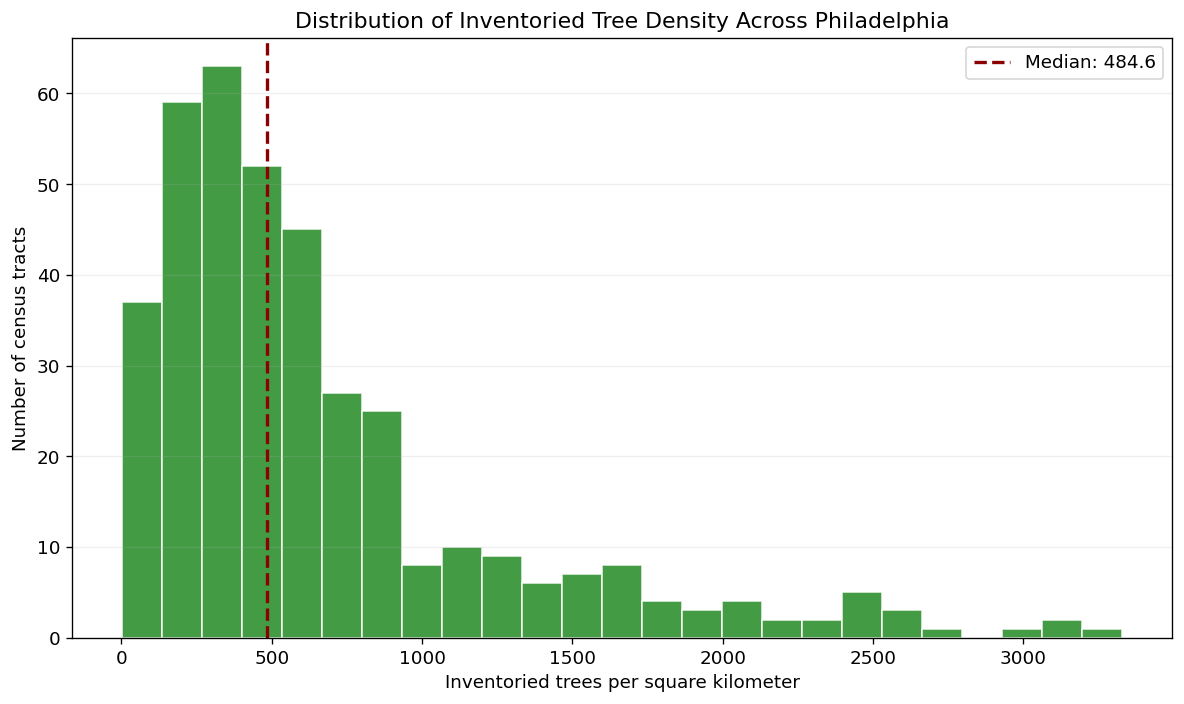

Tracts analyzed: 384
Mean density: 668.72
Median density: 484.63
Minimum density: 1.46
Maximum density: 3329.11


In [12]:

# PS2 - Histogram of inventoried tree density
import matplotlib.pyplot as plt
import numpy as np

tree_values = philly_tree_data["tree_density"].replace(
    [np.inf, -np.inf], np.nan
).dropna()

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    tree_values,
    bins=25,
    color="forestgreen",
    edgecolor="white",
    alpha=0.85
)

ax.axvline(
    tree_values.median(),
    color="darkred",
    linestyle="--",
    linewidth=2,
    label=f"Median: {tree_values.median():,.1f}"
)

ax.set_title("Distribution of Inventoried Tree Density Across Philadelphia")
ax.set_xlabel("Inventoried trees per square kilometer")
ax.set_ylabel("Number of census tracts")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

print("Tracts analyzed:", len(tree_values))
print("Mean density:", round(tree_values.mean(), 2))
print("Median density:", round(tree_values.median(), 2))
print("Minimum density:", round(tree_values.min(), 2))
print("Maximum density:", round(tree_values.max(), 2))

### Interpretation: Distribution of Inventoried Tree Density

The histogram shows a right-skewed distribution of inventoried tree density across 384 Philadelphia census tracts. The median density is 484.63 trees per square kilometer, while the mean is higher at 668.72 trees per square kilometer. This suggests that a relatively small number of tracts have particularly high densities of inventoried trees.

The results indicate substantial geographic variation in recorded tree distribution. However, tree inventory density does not necessarily represent total tree canopy coverage, since not every tree may be included in the inventory.

**Source:** Philadelphia Tree Inventory (2025), ArcGIS Hub / OpenDataPhilly.

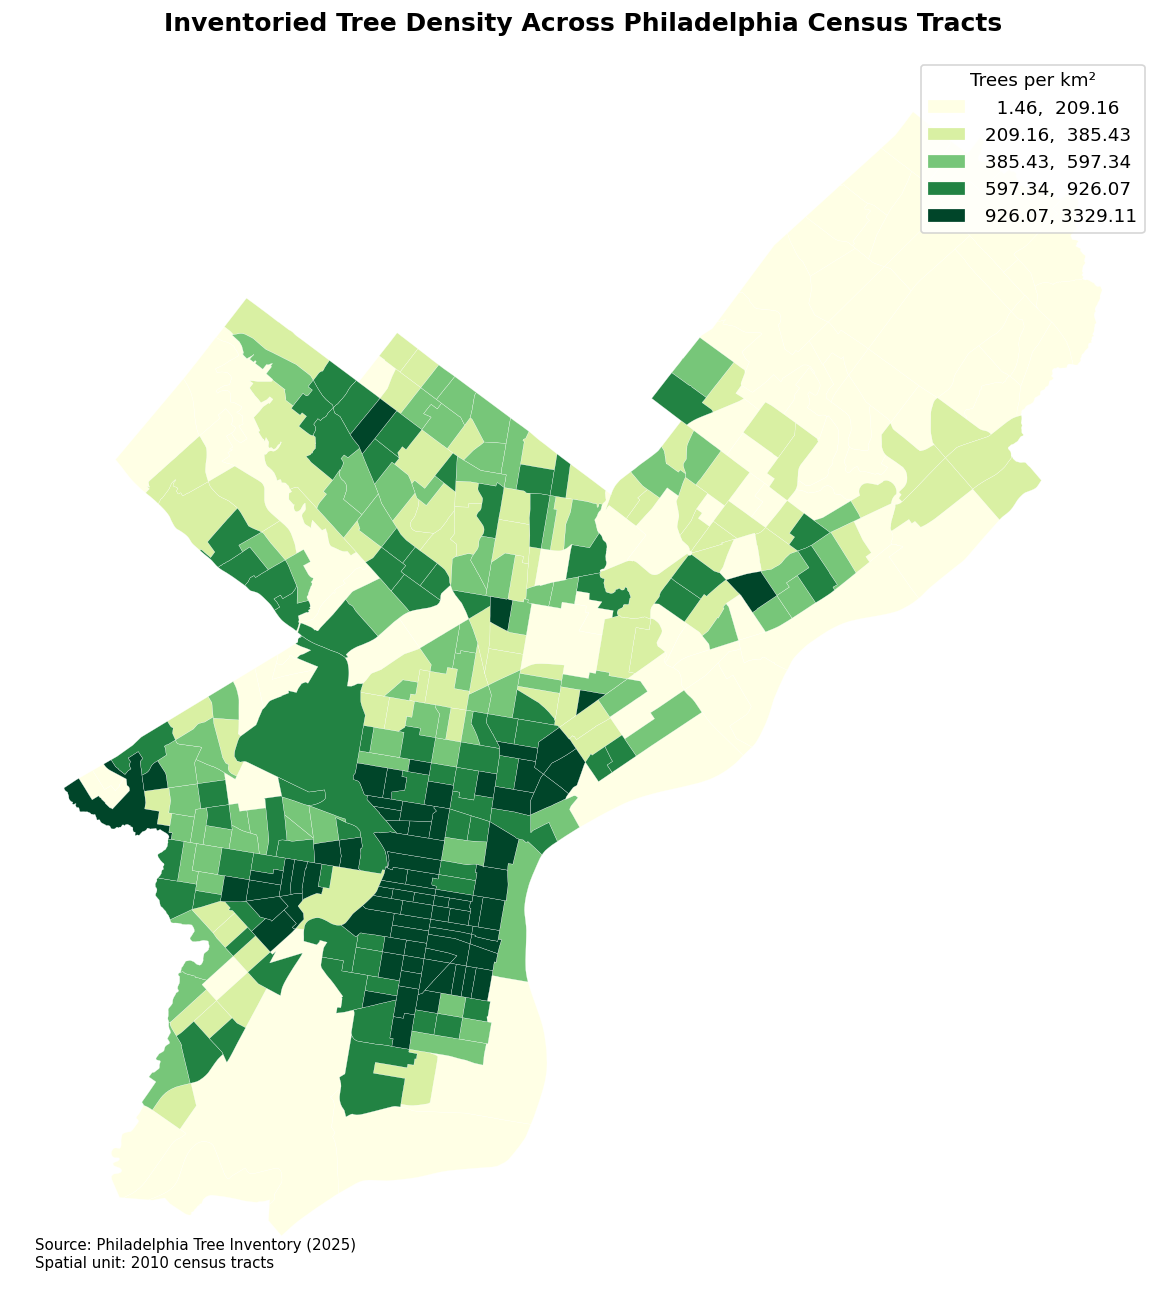

In [13]:

# PS2 - Geographic distribution of inventoried tree density
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 11))

philly_tree_data.plot(
    column="tree_density",
    cmap="YlGn",
    scheme="quantiles",
    k=5,
    legend=True,
    linewidth=0.15,
    edgecolor="white",
    ax=ax,
    legend_kwds={"title": "Trees per km²"}
)

ax.set_title(
    "Inventoried Tree Density Across Philadelphia Census Tracts",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_axis_off()

ax.text(
    0.02, 0.02,
    "Source: Philadelphia Tree Inventory (2025)\n"
    "Spatial unit: 2010 census tracts",
    transform=ax.transAxes,
    fontsize=9
)

plt.tight_layout()
plt.show()

### Map Interpretation: Geographic Distribution of Inventoried Trees

This choropleth map illustrates the geographic distribution of inventoried tree density across Philadelphia's 2010 census tracts, using the 2025 Philadelphia Tree Inventory.

The five green color categories represent different levels of inventoried trees per square kilometer. Darker green census tracts have higher recorded tree density, while lighter green tracts have lower density.

The map reveals considerable spatial variation in the distribution of inventoried trees across Philadelphia. This suggests that access to street-level greenery may differ across neighborhoods, although the inventory does not measure all vegetation or total tree canopy coverage.

**Data source:** Philadelphia Tree Inventory (2025), ArcGIS Hub / OpenDataPhilly.

In [14]:

# PS2 - Create the combined dataset for comparison maps
import pandas as pd

# Start with the tree-density data that already worked
philly_ps2 = philly_tree_data.copy()

# Add existing PS1 variables if available
if "philly_merged" in globals():
    ps1_data = philly_merged[
        ["geoid10", "asthma_pct", "env_val"]
    ].copy()

    ps1_data["geoid10"] = (
        ps1_data["geoid10"].astype(str).str.zfill(11)
    )
    philly_ps2["geoid10"] = (
        philly_ps2["geoid10"].astype(str).str.zfill(11)
    )

    philly_ps2 = philly_ps2.merge(
        ps1_data,
        on="geoid10",
        how="left"
    )
    philly_ps2 = philly_ps2.rename(
        columns={"env_val": "pm25"}
    )
else:
    print("PS1 data not loaded: philly_merged is missing.")

print("Dataset created:", len(philly_ps2), "census tracts")
print("Available columns:", philly_ps2.columns.tolist())

PS1 data not loaded: philly_merged is missing.
Dataset created: 384 census tracts
Available columns: ['geoid10', 'geometry', 'area_km2', 'tree_count', 'tree_density']


In [15]:

# Restore the original PS1 data from its source
import pandas as pd
import geopandas as gpd

tract_url = (
    "https://phl.carto.com/api/v2/sql"
    "?q=SELECT+*+FROM+census_tracts_2010&format=geojson"
)

cdc_url = (
    "https://data.cdc.gov/resource/cwsq-ngmh.csv"
    "?$limit=50000&stateabbr=PA"
)

phillyC0 = gpd.read_file(tract_url)
cdc_df = pd.read_csv(cdc_url)

phillyC0["GEOID10"] = (
    phillyC0["geoid10"].astype(str).str.zfill(11)
)
cdc_df["locationname"] = (
    cdc_df["locationname"].astype(str).str.zfill(11)
)
cdc_df["countyfips"] = (
    cdc_df["countyfips"].astype(str).str.zfill(5)
)
cdc_df["data_value"] = pd.to_numeric(
    cdc_df["data_value"], errors="coerce"
)

asthma_mask = (
    (cdc_df["countyfips"] == "42101") &
    cdc_df["measureid"].str.contains(
        "ASTHMA", case=False, na=False
    )
)

asthma = (
    cdc_df.loc[asthma_mask, ["locationname", "data_value"]]
    .drop_duplicates("locationname")
    .rename(columns={"data_value": "asthma_pct"})
)

philly_merged = phillyC0.merge(
    asthma,
    left_on="GEOID10",
    right_on="locationname",
    how="left"
)

print("PS1 data restored:", len(philly_merged), "tracts")
print("Asthma values available:",
      philly_merged["asthma_pct"].notna().sum())

PS1 data restored: 384 tracts
Asthma values available: 0


In [16]:

# Check which CDC indicators and locations are available
print("Total CDC records:", len(cdc_df))
print("\nCDC columns:")
print(cdc_df.columns.tolist())

print("\nAvailable asthma measures:")
display(
    cdc_df[
        cdc_df["measureid"].astype(str).str.contains(
            "ASTHMA", case=False, na=False
        )
    ][["measureid", "locationname", "countyfips", "data_value"]].head(10)
)

print("\nPhiladelphia county records:")
print((cdc_df["countyfips"] == "42101").sum())

Total CDC records: 17037

CDC columns:
['year', 'stateabbr', 'statedesc', 'countyname', 'countyfips', 'locationname', 'datasource', 'category', 'measure', 'data_value_unit', 'data_value_type', 'data_value', 'data_value_footnote_symbol', 'data_value_footnote', 'low_confidence_limit', 'high_confidence_limit', 'totalpopulation', 'totalpop18plus', 'geolocation', 'locationid', 'categoryid', 'measureid', 'datavaluetypeid', 'short_question_text']

Available asthma measures:


,measureid,locationname,countyfips,data_value



Philadelphia county records:
1945


In [17]:

# Find asthma-related indicators in the CDC dataset
philly_cdc = cdc_df[
    cdc_df["countyfips"] == "42101"
].copy()

print("Available CDC measures:")
display(
    philly_cdc[
        ["measureid", "measure"]
    ].drop_duplicates().sort_values("measure")
)

print("\nSample Philadelphia records:")
display(
    philly_cdc[
        ["year", "locationname", "measureid",
         "measure", "data_value"]
    ].head(10)
)

Available CDC measures:


,measureid,measure
1493,TEETHLOST,All teeth lost among adults aged >=65 years
1474,COLON_SCREEN,Colorectal cancer screening among adults aged ...
1560,MAMMOUSE,Mammography use among women aged 50-74 years
1473,SLEEP,Short sleep duration among adults
1513,DENTAL,Visited dentist or dental clinic in the past y...



Sample Philadelphia records:


,year,locationname,measureid,measure,data_value
1473,2022,42101012203,SLEEP,Short sleep duration among adults,37.1
1474,2022,42101034803,COLON_SCREEN,Colorectal cancer screening among adults aged ...,66.5
1493,2022,42101036600,TEETHLOST,All teeth lost among adults aged >=65 years,6.3
1513,2022,42101036302,DENTAL,Visited dentist or dental clinic in the past y...,59.2
1518,2022,42101003300,TEETHLOST,All teeth lost among adults aged >=65 years,20.9
1554,2022,42101038800,TEETHLOST,All teeth lost among adults aged >=65 years,3.9
1556,2022,42101039100,TEETHLOST,All teeth lost among adults aged >=65 years,44.5
1560,2022,42101016300,MAMMOUSE,Mammography use among women aged 50-74 years,72.2
1567,2022,42101028200,TEETHLOST,All teeth lost among adults aged >=65 years,34.1
1570,2022,42101030800,MAMMOUSE,Mammography use among women aged 50-74 years,76.6


In [18]:
# Inspect the original PS1 notebook's data-loading cells
for i, cell in enumerate(ps1_notebook.cells):
    if cell.cell_type == "code":
        print(f"\n{'='*20} CELL {i} {'='*20}")
        print(cell.source[:2500])


==================== CELL 2 ====================
%%capture
!pip install geopandas
!pip install mapclassify

==================== CELL 3 ====================
import os, zipfile #basics
import pandas as pd #data management
import matplotlib.pyplot as plt #vis

import geopandas as gpd #gis/maps: a sister of pandas; does the job
import mapclassify #need for thematic map classification
import seaborn as sns

#will display all output not just last command
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

from google.colab import files #to download from colab onto hd

from google.colab import data_table
#data_table.enable_dataframe_formatter() #this enables spreadsheet view upon calling dataframe
from google.colab.data_table import DataTable
DataTable.max_columns = 250

==================== CELL 4 ====================
# Check environment versions
import sys
print(f"Python Version: {sys.version.split()[0]}")
print(f"GeoPandas Version: 

In [19]:
# Find the original PS1 code for asthma and PM2.5
for i, cell in enumerate(ps1_notebook.cells):
    if cell.cell_type == "code":
        source = cell.source
        if any(word in source.lower() for word in
               ["asthma_pct", "env_val", "pm2.5", "environment"]):
            print(f"\n{'=' * 15} PS1 CELL {i} {'=' * 15}")
            print(source[:5000])


=============== PS1 CELL 4 ===============
# Check environment versions
import sys
print(f"Python Version: {sys.version.split()[0]}")
print(f"GeoPandas Version: {gpd.__version__}")

=============== PS1 CELL 15 ===============
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Standardize GEOID string formatting on both shapefile and CDC dataset
phillyC0['GEOID10'] = phillyC0['geoid10'].astype(str).str.zfill(11)

# Inspect CDC dataframe columns and clean keys
cdc_df['locationname'] = cdc_df['locationname'].astype(str).str.zfill(11)
cdc_df['countyfips'] = cdc_df['countyfips'].astype(str).str.zfill(5)

# Convert numeric column explicitly
cdc_df['data_value'] = pd.to_numeric(cdc_df['data_value'], errors='coerce')

# 2. Extract Asthma prevalence for Philadelphia (FIPS: 42101)
asthma_mask = (cdc_df['countyfips'] == '42101') & (cdc_df['measureid'].str.upper().str.contains('ASTHMA', na=False))
philly_asthma = cdc_df[asthma_mask][['locationname', 'data_value']].drop_d

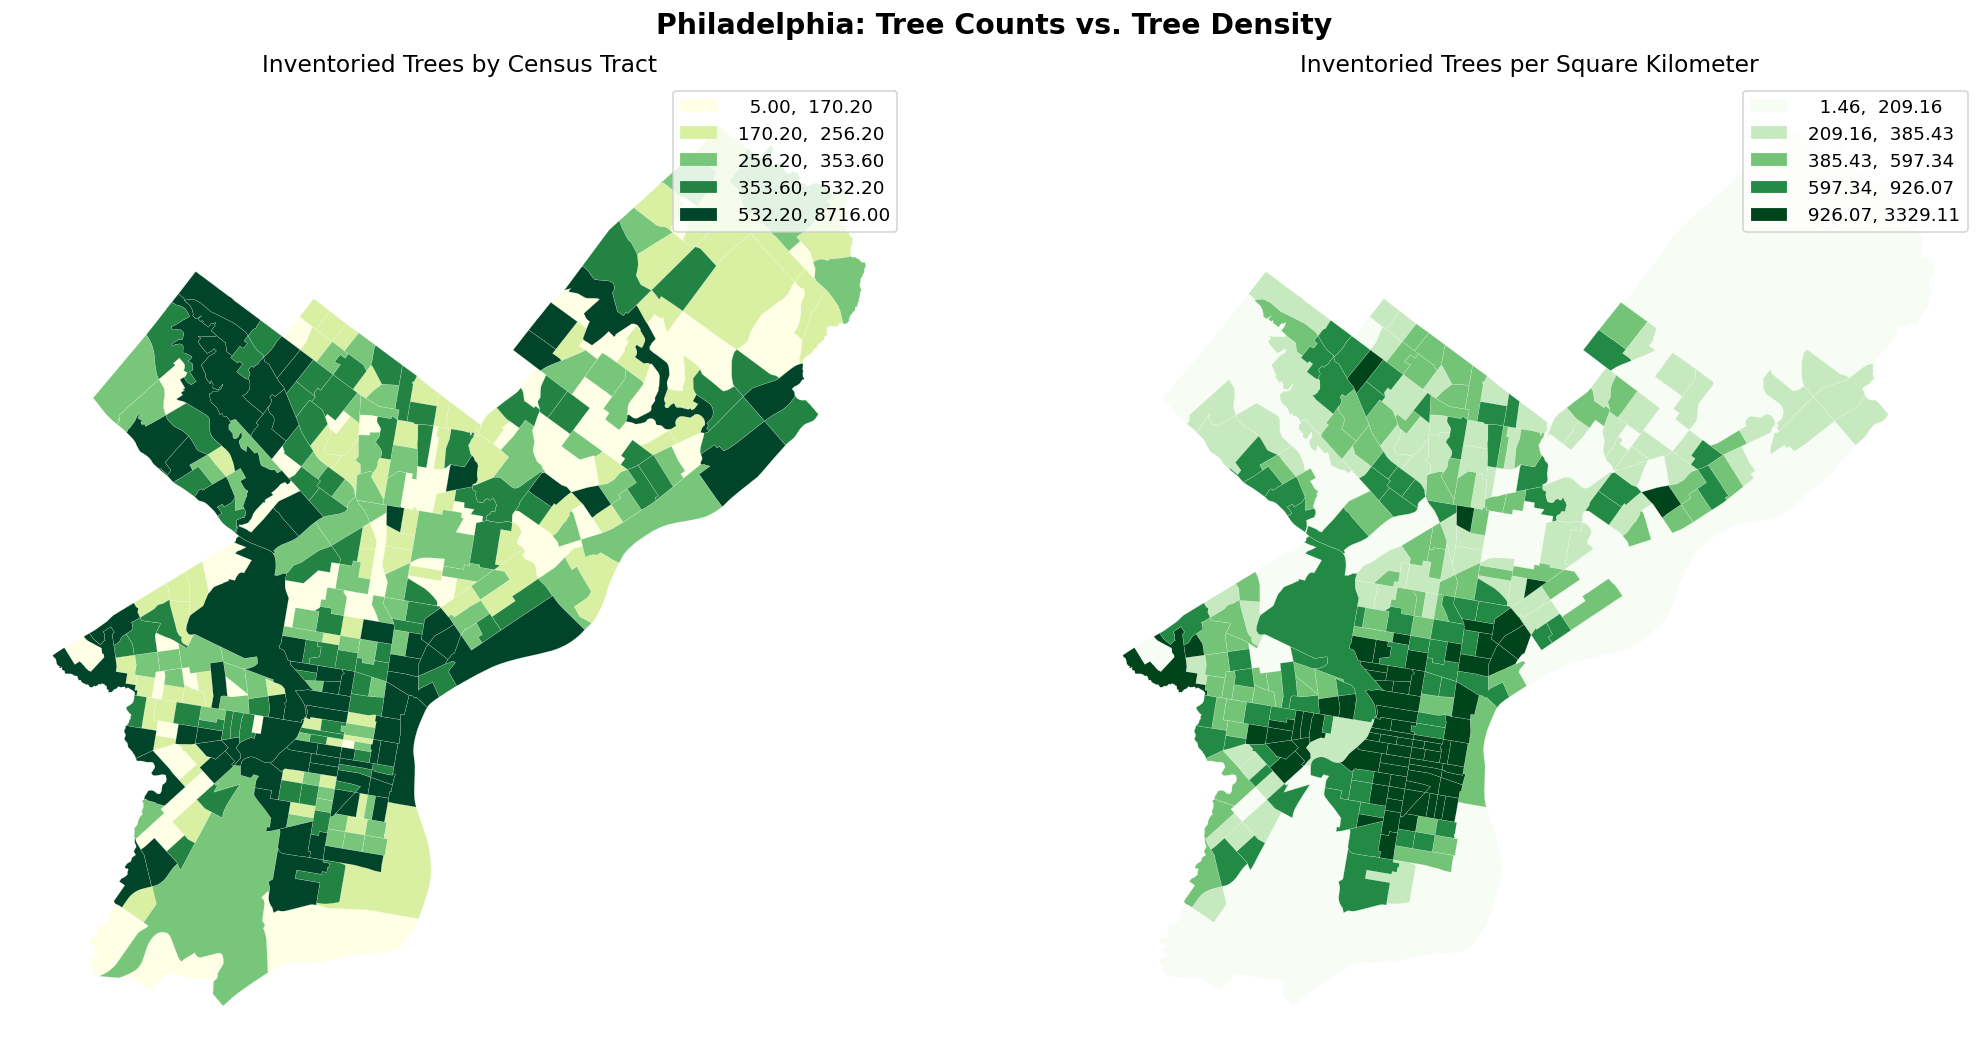

In [20]:
# PS2 - Map tree counts and tree density side by side
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(18, 9))

philly_tree_data.plot(
    column="tree_count",
    cmap="YlGn",
    scheme="quantiles",
    k=5,
    legend=True,
    ax=axes[0],
    edgecolor="white",
    linewidth=0.1
)
axes[0].set_title("Inventoried Trees by Census Tract", fontsize=14)
axes[0].set_axis_off()

philly_tree_data.plot(
    column="tree_density",
    cmap="Greens",
    scheme="quantiles",
    k=5,
    legend=True,
    ax=axes[1],
    edgecolor="white",
    linewidth=0.1
)
axes[1].set_title("Inventoried Trees per Square Kilometer", fontsize=14)
axes[1].set_axis_off()

fig.suptitle(
    "Philadelphia: Tree Counts vs. Tree Density",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### PS2 — Interpretation of Tree Distribution

The two maps illustrate differences in inventoried tree distribution across Philadelphia census tracts.

The first map represents the total number of inventoried trees, while the second map represents the number of inventoried trees per square kilometer. Both maps use five quantile categories to highlight geographic variation.

The comparison demonstrates that total tree counts and tree density do not always follow the same geographic pattern. Some larger census tracts contain many trees but have relatively low tree density. Smaller tracts can have fewer trees overall while showing higher concentrations per square kilometer.

These findings highlight why geographic area should be considered when comparing environmental resources across neighborhoods.

**Limitation:** The maps represent inventoried trees rather than complete tree canopy coverage. They should not be interpreted as measuring every tree in Philadelphia.

In [21]:
# PS2 - Verify data integration
print("=== PS2 DATA INTEGRATION CHECK ===")

print("\nTree dataset:")
print("Rows:", len(philly_tree_data))
print("Columns:", philly_tree_data.columns.tolist())

print("\nCombined PS2 dataset:")
print("Rows:", len(philly_ps2))
print("Columns:", philly_ps2.columns.tolist())

print("\nAvailable variables:")
for col in ["tree_count", "tree_density", "asthma_pct", "pm25"]:
    print(f"{col}: {'Available' if col in philly_ps2.columns else 'Missing'}")

print("\nMissing values:")
print(philly_ps2.isna().sum())

=== PS2 DATA INTEGRATION CHECK ===

Tree dataset:
Rows: 384
Columns: ['geoid10', 'geometry', 'area_km2', 'tree_count', 'tree_density']

Combined PS2 dataset:
Rows: 384
Columns: ['geoid10', 'geometry', 'area_km2', 'tree_count', 'tree_density']

Available variables:
tree_count: Available
tree_density: Available
asthma_pct: Missing
pm25: Missing

Missing values:
geoid10         0
geometry        0
area_km2        0
tree_count      0
tree_density    0
dtype: int64


In [22]:
# Check which original datasets are available
for name in ["phillyC0", "philly_merged", "cdc_df", "philly_tree_data"]:
    if name in globals():
        df = globals()[name]
        print(f"{name}: {len(df)} rows")
        print("Columns:", df.columns.tolist())
    else:
        print(f"{name}: NOT LOADED")
    print("-" * 50)

phillyC0: 384 rows
Columns: ['cartodb_id', 'objectid', 'statefp10', 'countyfp10', 'tractce10', 'geoid10', 'name10', 'namelsad10', 'mtfcc10', 'funcstat10', 'aland10', 'awater10', 'intptlat10', 'intptlon10', 'logrecno', 'name10_padded', 'geometry', 'GEOID10']
--------------------------------------------------
philly_merged: 384 rows
Columns: ['cartodb_id', 'objectid', 'statefp10', 'countyfp10', 'tractce10', 'geoid10', 'name10', 'namelsad10', 'mtfcc10', 'funcstat10', 'aland10', 'awater10', 'intptlat10', 'intptlon10', 'logrecno', 'name10_padded', 'geometry', 'GEOID10', 'locationname', 'asthma_pct']
--------------------------------------------------
cdc_df: 17037 rows
Columns: ['year', 'stateabbr', 'statedesc', 'countyname', 'countyfips', 'locationname', 'datasource', 'category', 'measure', 'data_value_unit', 'data_value_type', 'data_value', 'data_value_footnote_symbol', 'data_value_footnote', 'low_confidence_limit', 'high_confidence_limit', 'totalpopulation', 'totalpop18plus', 'geolocation

In [23]:
import pandas as pd

# Select a real CDC health indicator for Philadelphia
sleep = cdc_df[
    (cdc_df["countyfips"].astype(str).str.zfill(5) == "42101") &
    (cdc_df["measureid"] == "SLEEP")
].copy()

sleep["locationname"] = sleep["locationname"].astype(str).str.zfill(11)
sleep["data_value"] = pd.to_numeric(sleep["data_value"], errors="coerce")

# Retain the most recent observation for each tract
sleep["year"] = pd.to_numeric(sleep["year"], errors="coerce")
sleep = (
    sleep.sort_values("year")
    .drop_duplicates("locationname", keep="last")
    [["locationname", "data_value"]]
    .rename(columns={
        "locationname": "geoid10",
        "data_value": "sleep_pct"
    })
)

# Combine census tract boundaries, tree inventory and CDC health data
tracts = phillyC0[["geoid10", "geometry"]].copy()
tracts["geoid10"] = tracts["geoid10"].astype(str).str.zfill(11)

trees = philly_tree_data[
    ["geoid10", "tree_count", "tree_density"]
].copy()
trees["geoid10"] = trees["geoid10"].astype(str).str.zfill(11)

philly_ps2 = tracts.merge(
    trees, on="geoid10", how="left", validate="one_to_one"
)

philly_ps2 = philly_ps2.merge(
    sleep, on="geoid10", how="left", validate="one_to_one"
)

print("Total tracts:", len(philly_ps2))
print("Tree observations:", philly_ps2["tree_density"].notna().sum())
print("Matched sleep observations:", philly_ps2["sleep_pct"].notna().sum())
print("Columns:", philly_ps2.columns.tolist())

Total tracts: 384
Tree observations: 384
Matched sleep observations: 357
Columns: ['geoid10', 'geometry', 'tree_count', 'tree_density', 'sleep_pct']


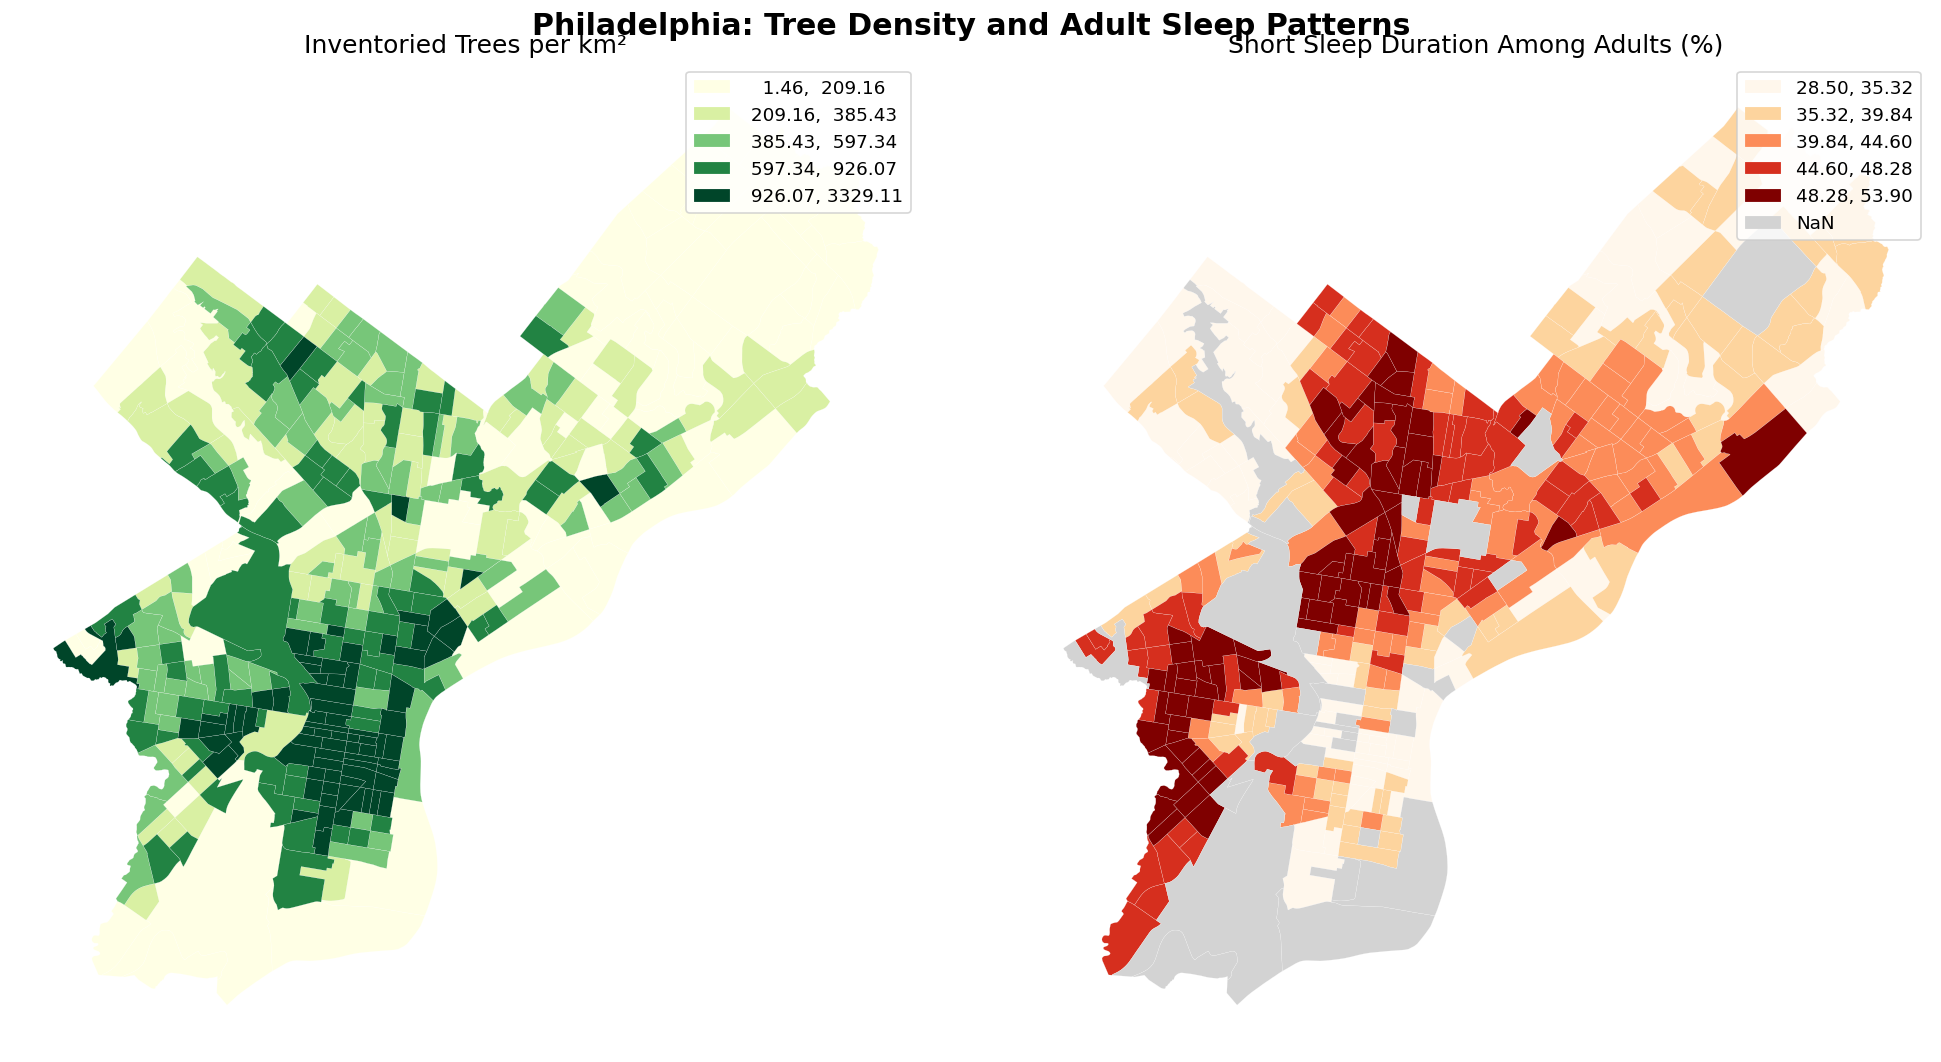

In [24]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(17, 9))

philly_ps2.plot(
    column="tree_density",
    cmap="YlGn",
    scheme="quantiles",
    k=5,
    legend=True,
    ax=axes[0],
    edgecolor="white",
    linewidth=0.1
)
axes[0].set_title("Inventoried Trees per km²", fontsize=15)
axes[0].set_axis_off()

philly_ps2.plot(
    column="sleep_pct",
    cmap="OrRd",
    scheme="quantiles",
    k=5,
    legend=True,
    ax=axes[1],
    edgecolor="white",
    linewidth=0.1,
    missing_kwds={"color": "lightgrey"}
)
axes[1].set_title("Short Sleep Duration Among Adults (%)", fontsize=15)
axes[1].set_axis_off()

fig.suptitle(
    "Philadelphia: Tree Density and Adult Sleep Patterns",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [25]:
import pandas as pd

# Third merge: add tract area from the geographic dataset
areas = philly_tree_data[
    ["geoid10", "area_km2"]
].copy()

areas["geoid10"] = areas["geoid10"].astype(str).str.zfill(11)

philly_ps2 = philly_ps2.merge(
    areas,
    on="geoid10",
    how="left",
    validate="one_to_one"
)

# Analyze tree density and adult short sleep
analysis = philly_ps2[
    ["tree_density", "sleep_pct"]
].dropna()

print("=== PS2 FINAL ANALYSIS ===")
print("Total census tracts:", len(philly_ps2))
print("Tracts with complete data:", len(analysis))
print("Pearson correlation:",
      round(analysis["tree_density"].corr(analysis["sleep_pct"]), 3))
print("Spearman correlation:",
      round(analysis["tree_density"].corr(
          analysis["sleep_pct"], method="spearman"
      ), 3))

display(analysis.describe().round(2))

=== PS2 FINAL ANALYSIS ===
Total census tracts: 384
Tracts with complete data: 357
Pearson correlation: -0.388
Spearman correlation: -0.158


,tree_density,sleep_pct
count,357.00,357.00
mean,654.93,41.88
std,600.08,6.34
min,21.52,28.50
25%,269.25,36.40
50%,478.80,42.40
75%,785.02,47.30
max,3329.11,53.90


## PS2 — Findings and Conclusion

### Research Question
How does inventoried tree density vary across Philadelphia census tracts, and how does it relate to the estimated prevalence of short sleep duration among adults?

### Data Integration
This analysis combines Philadelphia census tract boundaries, inventoried tree counts and density, and CDC PLACES estimates of short sleep duration. The resulting dataset contains 384 census tracts, with 357 complete observations for the correlation analysis.

### Key Findings
The maps reveal substantial geographic differences in inventoried tree density and adult short sleep prevalence.

The Pearson correlation between tree density and short sleep prevalence is **−0.388**, while the Spearman correlation is **−0.158**. These results indicate a negative association in the matched dataset, although its strength depends on the correlation method.

### Limitations
The results are observational and do not establish causation. Inventoried trees do not represent all urban vegetation. Census tract boundaries may also differ between the geographic and health datasets, and these differences require validation before drawing firm geographic conclusions.

### Conclusion
The project demonstrates how geographic data integration and thematic mapping can help explore environmental and public health patterns across Philadelphia. Further analysis should reconcile census tract boundaries and consider additional factors such as population density, income, and neighborhood characteristics.